# Phase 4: Detection and Change Tracking
This notebook implements Phase 4 for the Da Nang Sentinel-2 assignment.

Manual requirements covered here:
1. Detect and label a class of interest: built-up / urban-proxy regions.
2. Use Phase 3 co-registration homographies to warp 2026 onto the 2024 frame.
3. Compute difference maps and outline the strongest changed regions.
4. Discuss likely false-change sources and the controls used to reduce them.

All outputs are saved to `../output` with the prefix `phase4_`. This notebook does not modify Phase 1, Phase 2, Phase 3, or the report.


In [1]:
import csv
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from matplotlib.patches import Rectangle

# Paths are relative to this notebook when run from the works directory.
dataset_dir = Path("../dataset")
output_dir = Path("../output")
output_dir.mkdir(parents=True, exist_ok=True)

homography_path = output_dir / "phase3_homographies.json"
if not homography_path.exists():
    raise FileNotFoundError(
        "Phase 4 needs Phase 3 homographies. Run works/cpvass_phase3.ipynb first "
        "or provide ../output/phase3_homographies.json."
    )

with homography_path.open() as f:
    phase3_homographies = json.load(f)

dates = {
    "2024": {"folder": dataset_dir / "2024_04_11", "suffix": "2024", "label": "April 11, 2024"},
    "2026": {"folder": dataset_dir / "2026_04_11", "suffix": "2026", "label": "April 11, 2026"},
}

crops = {
    "above": "Upper AOI crop",
    "below": "Lower AOI crop",
}

print(f"Dataset directory: {dataset_dir.resolve()}")
print(f"Output directory: {output_dir.resolve()}")
print(f"Loaded Phase 3 homographies from: {homography_path}")


Dataset directory: /home/dacekey/CPV301_SUM26/main/L27_Assignment_*/dataset
Output directory: /home/dacekey/CPV301_SUM26/main/L27_Assignment_*/output
Loaded Phase 3 homographies from: ../output/phase3_homographies.json


In [2]:
def find_one(folder, pattern):
    matches = sorted(folder.glob(pattern))
    if not matches:
        raise FileNotFoundError(f"No file matching {pattern!r} in {folder}")
    if len(matches) > 1:
        print(f"Warning: multiple matches for {pattern!r} in {folder}; using {matches[0].name}")
    return matches[0]


def crop_folder(date_key, crop_key):
    config = dates[date_key]
    return config["folder"] / f"{crop_key}_{config['suffix']}"


def normalize_to_uint8(image):
    return cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)


def load_true_color(path):
    image = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if image is None:
        raise FileNotFoundError(f"Cannot load image: {path}")
    if image.ndim != 3 or image.shape[2] < 3:
        raise ValueError(f"Expected a 3-channel true-color image for {path}, got shape {image.shape}")
    rgb = cv2.cvtColor(image[:, :, :3], cv2.COLOR_BGR2RGB)
    return normalize_to_uint8(rgb)


def load_band(path):
    band = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if band is None:
        raise FileNotFoundError(f"Cannot load image: {path}")
    if band.ndim != 2:
        raise ValueError(f"Expected single-band TIFF for {path}, got shape {band.shape}")
    return band.astype(np.float32)


def load_scene(date_key, crop_key):
    folder = crop_folder(date_key, crop_key)
    rgb = load_true_color(find_one(folder, "*True_color*.tiff"))
    bands = {
        "B02": load_band(find_one(folder, "*B02*.tiff")),
        "B03": load_band(find_one(folder, "*B03*.tiff")),
        "B04": load_band(find_one(folder, "*B04*.tiff")),
        "B08": load_band(find_one(folder, "*B08*.tiff")),
    }
    for name, band in bands.items():
        if band.shape != rgb.shape[:2]:
            raise ValueError(f"Shape mismatch for {date_key}/{crop_key}/{name}: {band.shape} vs {rgb.shape[:2]}")
    return {"rgb": rgb, "bands": bands}


def safe_index(numerator, denominator):
    return np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator, dtype=np.float32),
        where=denominator != 0,
    )


def calculate_ndvi(red, nir):
    return safe_index(nir - red, nir + red)


def calculate_ndwi(green, nir):
    return safe_index(green - nir, green + nir)


def warp_scene_to_fixed(moving_scene, homography, fixed_shape):
    height, width = fixed_shape[:2]
    warped_rgb = cv2.warpPerspective(moving_scene["rgb"], homography, (width, height))
    warped_bands = {
        name: cv2.warpPerspective(band, homography, (width, height))
        for name, band in moving_scene["bands"].items()
    }
    valid_mask = cv2.warpPerspective(
        np.ones(moving_scene["rgb"].shape[:2], dtype=np.uint8) * 255,
        homography,
        (width, height),
    ) > 0
    return {"rgb": warped_rgb, "bands": warped_bands, "valid_mask": valid_mask}


def save_figure(fig, filename):
    path = output_dir / filename
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved: {path}")
    return path


def save_rgb_image(image, filename):
    path = output_dir / filename
    Image.fromarray(image).save(path)
    print(f"Saved: {path}")
    return path


def clean_binary_mask(mask, open_size=3, close_size=5):
    output = mask.astype(np.uint8)
    if open_size:
        output = cv2.morphologyEx(output, cv2.MORPH_OPEN, np.ones((open_size, open_size), dtype=np.uint8))
    if close_size:
        output = cv2.morphologyEx(output, cv2.MORPH_CLOSE, np.ones((close_size, close_size), dtype=np.uint8))
    return output.astype(bool)


def draw_mask_overlay(rgb, masks, alpha=0.45):
    overlay = rgb.copy().astype(np.float32)
    for mask, color in masks:
        if mask is None:
            continue
        overlay[mask] = (1 - alpha) * overlay[mask] + alpha * np.array(color, dtype=np.float32)
    return np.clip(overlay, 0, 255).astype(np.uint8)


def draw_contours(rgb, mask, color=(255, 255, 0), thickness=2):
    output = rgb.copy()
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(output, contours, -1, color, thickness)
    return output


def connected_regions(mask, min_area=60, max_regions=None):
    count, labels, stats, centroids = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    regions = []
    for label_id in range(1, count):
        area = int(stats[label_id, cv2.CC_STAT_AREA])
        if area < min_area:
            continue
        x = int(stats[label_id, cv2.CC_STAT_LEFT])
        y = int(stats[label_id, cv2.CC_STAT_TOP])
        w = int(stats[label_id, cv2.CC_STAT_WIDTH])
        h = int(stats[label_id, cv2.CC_STAT_HEIGHT])
        cx, cy = centroids[label_id]
        regions.append({
            "label_id": int(label_id),
            "area_px": area,
            "bbox_x": x,
            "bbox_y": y,
            "bbox_w": w,
            "bbox_h": h,
            "centroid_x": float(cx),
            "centroid_y": float(cy),
        })
    regions.sort(key=lambda r: r["area_px"], reverse=True)
    if max_regions is not None:
        regions = regions[:max_regions]
    return regions, labels


In [3]:
label_names = {
    0: "Water",
    1: "Dense vegetation",
    2: "Built-up/urban proxy",
    3: "Sand/exposed soil",
    4: "Mixed/shadow/other",
}

label_colors = np.array([
    [37, 99, 235],     # water: blue
    [34, 139, 34],     # vegetation: green
    [220, 38, 38],     # built-up/urban proxy: red
    [245, 158, 11],    # sand/exposed soil: orange
    [107, 114, 128],   # mixed/shadow/other: gray
], dtype=np.uint8)


def classify_landcover(scene, valid_mask=None):
    rgb = scene["rgb"]
    bands = scene["bands"]
    red = bands["B04"]
    green = bands["B03"]
    nir = bands["B08"]

    ndvi = calculate_ndvi(red, nir)
    ndwi = calculate_ndwi(green, nir)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    saturation = hsv[:, :, 1]

    if valid_mask is None:
        valid_mask = np.ones(gray.shape, dtype=bool)

    water = (((ndwi > 0.05) & (ndvi < 0.10)) | ((gray < 70) & (ndvi < 0.15))) & valid_mask
    vegetation = (ndvi > 0.35) & valid_mask
    cloud = (gray > 195) & (saturation < 80) & (ndvi < 0.35) & valid_mask
    shadow = (gray < 38) & (ndvi < 0.30) & valid_mask

    built = (~water) & (~vegetation) & (ndvi < 0.25) & (gray > 110) & (saturation < 130) & (~cloud) & (~shadow) & valid_mask
    sand = (~water) & (~vegetation) & (~built) & (ndvi > -0.25) & (ndvi < 0.20) & (gray > 80) & (saturation < 100) & valid_mask

    labels = np.full(gray.shape, 4, dtype=np.uint8)
    labels[water] = 0
    labels[vegetation] = 1
    labels[built] = 2
    labels[sand] = 3
    labels[~valid_mask] = 4

    built_clean = clean_binary_mask(built, open_size=3, close_size=5)
    label_image = label_colors[labels]

    return {
        "ndvi": ndvi,
        "ndwi": ndwi,
        "gray": gray,
        "saturation": saturation,
        "valid_mask": valid_mask,
        "water": water,
        "vegetation": vegetation,
        "built": built_clean,
        "sand": sand,
        "cloud": cloud,
        "shadow": shadow,
        "labels": labels,
        "label_image": label_image,
    }

scene_data = {}
analysis_data = {}

for crop_key, crop_label in crops.items():
    fixed_2024 = load_scene("2024", crop_key)
    moving_2026 = load_scene("2026", crop_key)
    homography = np.array(phase3_homographies["coregistration"][crop_key], dtype=np.float64)
    aligned_2026 = warp_scene_to_fixed(moving_2026, homography, fixed_2024["rgb"].shape)

    scene_data[("2024", crop_key)] = fixed_2024
    scene_data[("2026_aligned", crop_key)] = aligned_2026

    analysis_data[("2024", crop_key)] = classify_landcover(fixed_2024)
    analysis_data[("2026_aligned", crop_key)] = classify_landcover(aligned_2026, aligned_2026["valid_mask"])

    print(
        f"Loaded and co-registered {crop_label}: "
        f"2024 shape={fixed_2024['rgb'].shape}, aligned 2026 shape={aligned_2026['rgb'].shape}"
    )


Loaded and co-registered Upper AOI crop: 2024 shape=(252, 774, 3), aligned 2026 shape=(252, 774, 3)
Loaded and co-registered Lower AOI crop: 2024 shape=(313, 743, 3), aligned 2026 shape=(313, 743, 3)


Saved: ../output/phase4_builtup_detection_2024_2026.png
Saved: ../output/phase4_builtup_detection_regions.csv
Saved: ../output/phase4_landcover_area_summary.csv

Built-up detection summary
- above / 2024: built-up=1471 px (0.75%), labeled regions=1
- above / 2026_aligned: built-up=1893 px (0.97%), labeled regions=1
- below / 2024: built-up=25971 px (11.17%), labeled regions=10
- below / 2026_aligned: built-up=24184 px (10.40%), labeled regions=18


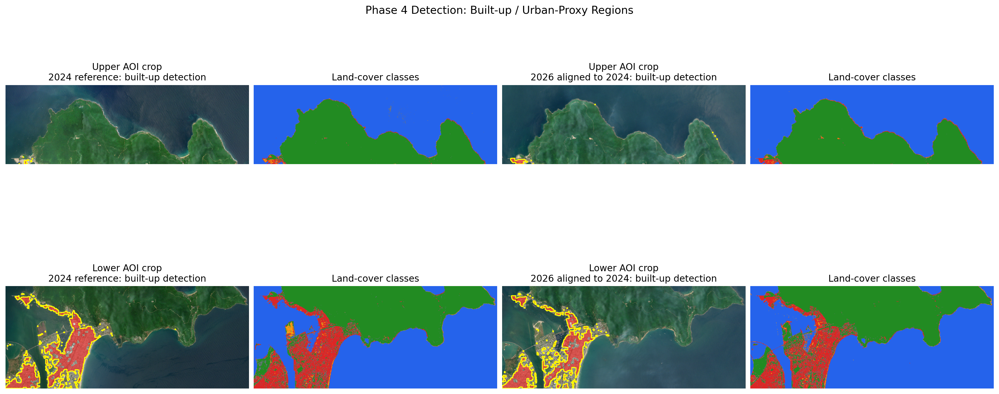

In [4]:
detection_rows = []
area_rows = []

fig, axes = plt.subplots(len(crops), 4, figsize=(18, 8), constrained_layout=True)

for row_idx, (crop_key, crop_label) in enumerate(crops.items()):
    for date_col, date_key in enumerate(["2024", "2026_aligned"]):
        scene = scene_data[(date_key, crop_key)]
        analysis = analysis_data[(date_key, crop_key)]
        built = analysis["built"]
        valid = analysis["valid_mask"]
        total_valid = int(np.count_nonzero(valid))

        built_regions, built_labels = connected_regions(built, min_area=50, max_regions=20)
        for idx, region in enumerate(built_regions, start=1):
            region_mask = built_labels == region["label_id"]
            detection_rows.append({
                "date": date_key,
                "crop": crop_key,
                "region_rank": idx,
                "area_px": region["area_px"],
                "bbox_x": region["bbox_x"],
                "bbox_y": region["bbox_y"],
                "bbox_w": region["bbox_w"],
                "bbox_h": region["bbox_h"],
                "centroid_x": region["centroid_x"],
                "centroid_y": region["centroid_y"],
                "mean_ndvi": float(np.mean(analysis["ndvi"][region_mask])),
                "mean_ndwi": float(np.mean(analysis["ndwi"][region_mask])),
            })

        for class_id, class_name in label_names.items():
            mask = (analysis["labels"] == class_id) & valid
            area_rows.append({
                "date": date_key,
                "crop": crop_key,
                "class_id": class_id,
                "class_name": class_name,
                "pixels": int(np.count_nonzero(mask)),
                "percent_valid": float(np.count_nonzero(mask) / total_valid * 100.0) if total_valid else 0.0,
            })

        overlay = draw_mask_overlay(scene["rgb"], [(built, (255, 0, 0))], alpha=0.50)
        contour_overlay = draw_contours(overlay, built, color=(255, 255, 0), thickness=2)
        label_image = analysis["label_image"]

        ax_overlay = axes[row_idx, date_col * 2]
        ax_labels = axes[row_idx, date_col * 2 + 1]
        title_date = "2024 reference" if date_key == "2024" else "2026 aligned to 2024"
        ax_overlay.imshow(contour_overlay)
        ax_overlay.set_title(f"{crop_label}\n{title_date}: built-up detection")
        ax_labels.imshow(label_image)
        ax_labels.set_title("Land-cover classes")
        ax_overlay.axis("off")
        ax_labels.axis("off")

fig.suptitle("Phase 4 Detection: Built-up / Urban-Proxy Regions", fontsize=14)
save_figure(fig, "phase4_builtup_detection_2024_2026.png")
plt.show()

regions_csv = output_dir / "phase4_builtup_detection_regions.csv"
with regions_csv.open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(detection_rows[0].keys()))
    writer.writeheader()
    writer.writerows(detection_rows)
print(f"Saved: {regions_csv}")

area_csv = output_dir / "phase4_landcover_area_summary.csv"
with area_csv.open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(area_rows[0].keys()))
    writer.writeheader()
    writer.writerows(area_rows)
print(f"Saved: {area_csv}")

print("\nBuilt-up detection summary")
for crop_key in crops:
    for date_key in ["2024", "2026_aligned"]:
        built_px = next(row["pixels"] for row in area_rows if row["crop"] == crop_key and row["date"] == date_key and row["class_id"] == 2)
        built_pct = next(row["percent_valid"] for row in area_rows if row["crop"] == crop_key and row["date"] == date_key and row["class_id"] == 2)
        region_count = sum(1 for row in detection_rows if row["crop"] == crop_key and row["date"] == date_key)
        print(f"- {crop_key} / {date_key}: built-up={built_px} px ({built_pct:.2f}%), labeled regions={region_count}")


Saved: ../output/phase4_builtup_change_tracking.png
Saved: ../output/phase4_builtup_change_regions.csv

Built-up change tracking summary
- above: gain regions=1 (180 px), loss/reclass regions=0 (0 px)
- below: gain regions=8 (588 px), loss/reclass regions=14 (3029 px)


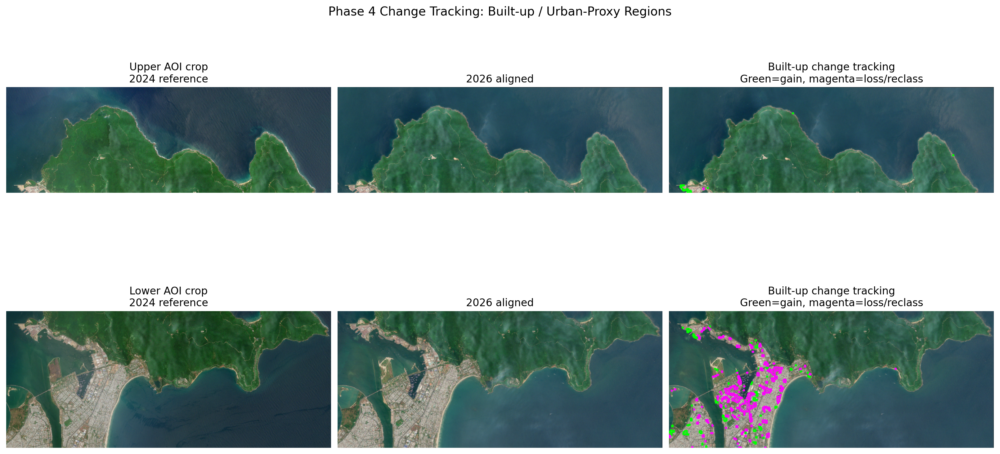

In [5]:
built_change_rows = []
fig, axes = plt.subplots(len(crops), 3, figsize=(16, 8), constrained_layout=True)

for row_idx, (crop_key, crop_label) in enumerate(crops.items()):
    scene_2024 = scene_data[("2024", crop_key)]
    scene_2026 = scene_data[("2026_aligned", crop_key)]
    a2024 = analysis_data[("2024", crop_key)]
    a2026 = analysis_data[("2026_aligned", crop_key)]

    valid = a2026["valid_mask"] & ~(a2024["cloud"] | a2026["cloud"] | a2024["shadow"] | a2026["shadow"])
    built_2024 = a2024["built"] & valid
    built_2026 = a2026["built"] & valid

    built_gain = clean_binary_mask(built_2026 & ~built_2024, open_size=3, close_size=5)
    built_loss = clean_binary_mask(built_2024 & ~built_2026, open_size=3, close_size=5)

    gain_regions, gain_labels = connected_regions(built_gain, min_area=50, max_regions=20)
    loss_regions, loss_labels = connected_regions(built_loss, min_area=50, max_regions=20)

    for change_type, regions, labels in [
        ("urban_proxy_gain", gain_regions, gain_labels),
        ("urban_proxy_loss_or_reclassification", loss_regions, loss_labels),
    ]:
        for idx, region in enumerate(regions, start=1):
            region_mask = labels == region["label_id"]
            built_change_rows.append({
                "crop": crop_key,
                "change_type": change_type,
                "region_rank": idx,
                "area_px": region["area_px"],
                "bbox_x": region["bbox_x"],
                "bbox_y": region["bbox_y"],
                "bbox_w": region["bbox_w"],
                "bbox_h": region["bbox_h"],
                "centroid_x": region["centroid_x"],
                "centroid_y": region["centroid_y"],
                "mean_ndvi_2024": float(np.mean(a2024["ndvi"][region_mask])),
                "mean_ndvi_2026_aligned": float(np.mean(a2026["ndvi"][region_mask])),
                "mean_ndvi_delta": float(np.mean(a2026["ndvi"][region_mask] - a2024["ndvi"][region_mask])),
            })

    overlay = draw_mask_overlay(
        scene_2026["rgb"],
        [(built_gain, (0, 255, 0)), (built_loss, (255, 0, 255))],
        alpha=0.60,
    )
    overlay = draw_contours(overlay, built_gain, color=(0, 255, 0), thickness=2)
    overlay = draw_contours(overlay, built_loss, color=(255, 0, 255), thickness=2)

    axes[row_idx, 0].imshow(scene_2024["rgb"])
    axes[row_idx, 0].set_title(f"{crop_label}\n2024 reference")
    axes[row_idx, 1].imshow(scene_2026["rgb"])
    axes[row_idx, 1].set_title("2026 aligned")
    axes[row_idx, 2].imshow(overlay)
    axes[row_idx, 2].set_title("Built-up change tracking\nGreen=gain, magenta=loss/reclass")
    for col_idx in range(3):
        axes[row_idx, col_idx].axis("off")

fig.suptitle("Phase 4 Change Tracking: Built-up / Urban-Proxy Regions", fontsize=14)
save_figure(fig, "phase4_builtup_change_tracking.png")
plt.show()

built_change_csv = output_dir / "phase4_builtup_change_regions.csv"
if built_change_rows:
    with built_change_csv.open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(built_change_rows[0].keys()))
        writer.writeheader()
        writer.writerows(built_change_rows)
else:
    with built_change_csv.open("w", newline="") as f:
        f.write("crop,change_type,region_rank,area_px,bbox_x,bbox_y,bbox_w,bbox_h,centroid_x,centroid_y,mean_ndvi_2024,mean_ndvi_2026_aligned,mean_ndvi_delta\n")
print(f"Saved: {built_change_csv}")

print("\nBuilt-up change tracking summary")
for crop_key in crops:
    gain_count = sum(1 for row in built_change_rows if row["crop"] == crop_key and row["change_type"] == "urban_proxy_gain")
    loss_count = sum(1 for row in built_change_rows if row["crop"] == crop_key and row["change_type"] == "urban_proxy_loss_or_reclassification")
    gain_area = sum(row["area_px"] for row in built_change_rows if row["crop"] == crop_key and row["change_type"] == "urban_proxy_gain")
    loss_area = sum(row["area_px"] for row in built_change_rows if row["crop"] == crop_key and row["change_type"] == "urban_proxy_loss_or_reclassification")
    print(f"- {crop_key}: gain regions={gain_count} ({gain_area} px), loss/reclass regions={loss_count} ({loss_area} px)")


Saved: ../output/phase4_difference_maps.png
Saved: ../output/phase4_top_change_regions_tracking.png
Saved: ../output/phase4_top_change_regions.csv

Top change-region summary
- above R1: area=247 px, score=0.097, NDVI delta=-0.091, built 0.0%->0.0%, mixed spectral change candidate
- above R2: area=166 px, score=0.096, NDVI delta=-0.090, built 0.0%->0.0%, mixed spectral change candidate
- above R3: area=67 px, score=0.100, NDVI delta=-0.056, built 0.0%->0.0%, mixed spectral change candidate
- above R4: area=67 px, score=0.097, NDVI delta=-0.089, built 0.0%->0.0%, mixed spectral change candidate
- above R5: area=53 px, score=0.181, NDVI delta=+0.217, built 0.0%->100.0%, urban-proxy gain candidate
- above R6: area=51 px, score=0.169, NDVI delta=+0.176, built 0.0%->0.0%, vegetation spectral change candidate
- below R1: area=903 px, score=0.237, NDVI delta=+0.317, built 3.8%->2.9%, vegetation spectral change candidate
- below R2: area=413 px, score=0.181, NDVI delta=-0.167, built 0.0%->0.0%,

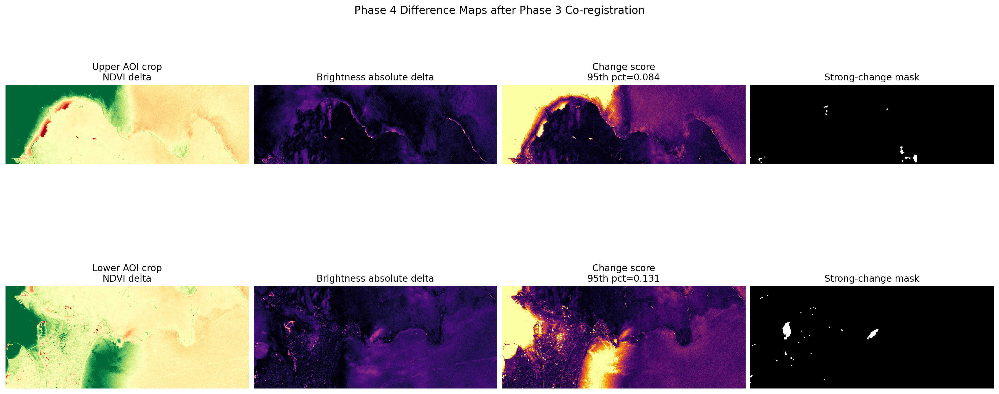

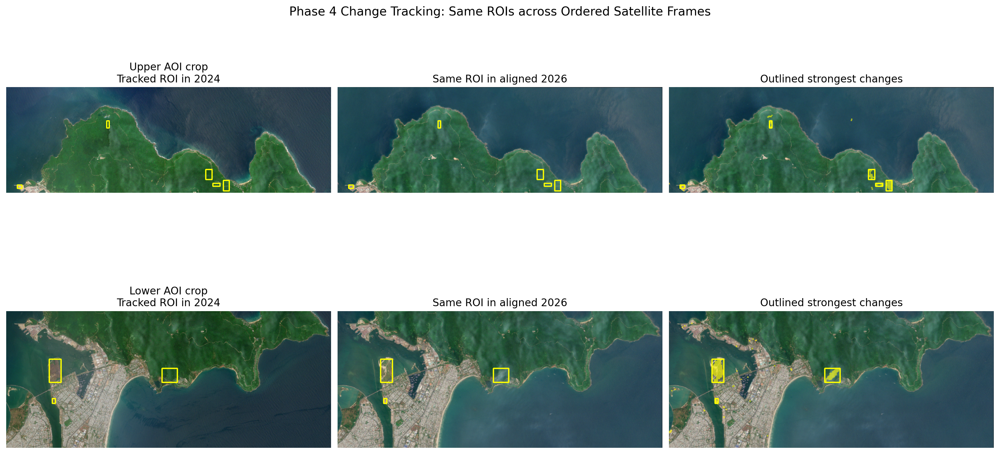

In [6]:
change_rows = []
change_maps = {}
fig_maps, axes_maps = plt.subplots(len(crops), 4, figsize=(18, 8), constrained_layout=True)
fig_regions, axes_regions = plt.subplots(len(crops), 3, figsize=(16, 8), constrained_layout=True)

for row_idx, (crop_key, crop_label) in enumerate(crops.items()):
    scene_2024 = scene_data[("2024", crop_key)]
    scene_2026 = scene_data[("2026_aligned", crop_key)]
    a2024 = analysis_data[("2024", crop_key)]
    a2026 = analysis_data[("2026_aligned", crop_key)]

    valid = a2026["valid_mask"]
    land = valid & ~(a2024["water"] & a2026["water"])
    clean_valid = land & ~(a2024["cloud"] | a2026["cloud"] | a2024["shadow"] | a2026["shadow"])

    ndvi_delta = a2026["ndvi"] - a2024["ndvi"]
    ndwi_delta = a2026["ndwi"] - a2024["ndwi"]
    gray_delta = a2026["gray"].astype(np.float32) - a2024["gray"].astype(np.float32)

    change_score = (
        0.45 * np.abs(ndvi_delta)
        + 0.35 * np.abs(gray_delta) / 255.0
        + 0.20 * np.abs(ndwi_delta)
    )
    threshold = float(np.percentile(change_score[clean_valid], 95)) if np.any(clean_valid) else float("nan")
    strong_change = (change_score >= threshold) & clean_valid
    strong_change = clean_binary_mask(strong_change, open_size=3, close_size=5)

    regions, labels = connected_regions(strong_change, min_area=50, max_regions=8)
    change_maps[crop_key] = {
        "change_score": change_score,
        "threshold": threshold,
        "strong_change": strong_change,
        "labels": labels,
        "regions": regions,
        "clean_valid": clean_valid,
    }

    for idx, region in enumerate(regions, start=1):
        region_mask = labels == region["label_id"]
        built_2024_pct = float(np.count_nonzero(a2024["built"] & region_mask) / region["area_px"] * 100.0)
        built_2026_pct = float(np.count_nonzero(a2026["built"] & region_mask) / region["area_px"] * 100.0)
        water_2024_pct = float(np.count_nonzero(a2024["water"] & region_mask) / region["area_px"] * 100.0)
        water_2026_pct = float(np.count_nonzero(a2026["water"] & region_mask) / region["area_px"] * 100.0)
        mean_ndvi_delta = float(np.mean(ndvi_delta[region_mask]))
        mean_score = float(np.mean(change_score[region_mask]))

        if built_2026_pct - built_2024_pct > 20:
            interpretation = "urban-proxy gain candidate"
        elif built_2024_pct - built_2026_pct > 20:
            interpretation = "urban-proxy loss/reclassification candidate"
        elif abs(water_2026_pct - water_2024_pct) > 20:
            interpretation = "water/shoreline or turbidity change candidate"
        elif abs(mean_ndvi_delta) > 0.15:
            interpretation = "vegetation spectral change candidate"
        else:
            interpretation = "mixed spectral change candidate"

        change_rows.append({
            "crop": crop_key,
            "region_rank": idx,
            "area_px": region["area_px"],
            "bbox_x": region["bbox_x"],
            "bbox_y": region["bbox_y"],
            "bbox_w": region["bbox_w"],
            "bbox_h": region["bbox_h"],
            "centroid_x": region["centroid_x"],
            "centroid_y": region["centroid_y"],
            "mean_change_score": mean_score,
            "mean_ndvi_2024": float(np.mean(a2024["ndvi"][region_mask])),
            "mean_ndvi_2026_aligned": float(np.mean(a2026["ndvi"][region_mask])),
            "mean_ndvi_delta": mean_ndvi_delta,
            "built_pct_2024": built_2024_pct,
            "built_pct_2026_aligned": built_2026_pct,
            "water_pct_2024": water_2024_pct,
            "water_pct_2026_aligned": water_2026_pct,
            "interpretation": interpretation,
        })

    # Difference-map panel.
    axes_maps[row_idx, 0].imshow(ndvi_delta, cmap="RdYlGn", vmin=-0.5, vmax=0.5)
    axes_maps[row_idx, 0].set_title(f"{crop_label}\nNDVI delta")
    axes_maps[row_idx, 1].imshow(np.abs(gray_delta), cmap="magma", vmin=0, vmax=120)
    axes_maps[row_idx, 1].set_title("Brightness absolute delta")
    axes_maps[row_idx, 2].imshow(change_score, cmap="inferno", vmin=0, vmax=max(0.30, threshold))
    axes_maps[row_idx, 2].set_title(f"Change score\n95th pct={threshold:.3f}")
    axes_maps[row_idx, 3].imshow(strong_change, cmap="gray")
    axes_maps[row_idx, 3].set_title("Strong-change mask")
    for col_idx in range(4):
        axes_maps[row_idx, col_idx].axis("off")

    # Region tracking panel.
    outlined_2024 = scene_2024["rgb"].copy()
    outlined_2026 = scene_2026["rgb"].copy()
    change_overlay = draw_mask_overlay(scene_2026["rgb"], [(strong_change, (255, 255, 0))], alpha=0.60)
    for region in regions[:5]:
        x, y, w, h = region["bbox_x"], region["bbox_y"], region["bbox_w"], region["bbox_h"]
        cv2.rectangle(outlined_2024, (x, y), (x + w, y + h), (255, 255, 0), 2)
        cv2.rectangle(outlined_2026, (x, y), (x + w, y + h), (255, 255, 0), 2)
        cv2.rectangle(change_overlay, (x, y), (x + w, y + h), (255, 255, 0), 2)
    axes_regions[row_idx, 0].imshow(outlined_2024)
    axes_regions[row_idx, 0].set_title(f"{crop_label}\nTracked ROI in 2024")
    axes_regions[row_idx, 1].imshow(outlined_2026)
    axes_regions[row_idx, 1].set_title("Same ROI in aligned 2026")
    axes_regions[row_idx, 2].imshow(change_overlay)
    axes_regions[row_idx, 2].set_title("Outlined strongest changes")
    for col_idx in range(3):
        axes_regions[row_idx, col_idx].axis("off")

fig_maps.suptitle("Phase 4 Difference Maps after Phase 3 Co-registration", fontsize=14)
save_figure(fig_maps, "phase4_difference_maps.png")
plt.show()

fig_regions.suptitle("Phase 4 Change Tracking: Same ROIs across Ordered Satellite Frames", fontsize=14)
save_figure(fig_regions, "phase4_top_change_regions_tracking.png")
plt.show()

change_csv = output_dir / "phase4_top_change_regions.csv"
if change_rows:
    with change_csv.open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(change_rows[0].keys()))
        writer.writeheader()
        writer.writerows(change_rows)
else:
    with change_csv.open("w", newline="") as f:
        f.write("crop,region_rank,area_px,bbox_x,bbox_y,bbox_w,bbox_h,centroid_x,centroid_y,mean_change_score,mean_ndvi_2024,mean_ndvi_2026_aligned,mean_ndvi_delta,built_pct_2024,built_pct_2026_aligned,water_pct_2024,water_pct_2026_aligned,interpretation\n")
print(f"Saved: {change_csv}")

print("\nTop change-region summary")
for row in change_rows[:12]:
    print(
        f"- {row['crop']} R{row['region_rank']}: area={row['area_px']} px, "
        f"score={row['mean_change_score']:.3f}, NDVI delta={row['mean_ndvi_delta']:+.3f}, "
        f"built {row['built_pct_2024']:.1f}%->{row['built_pct_2026_aligned']:.1f}%, "
        f"{row['interpretation']}"
    )


Saved: ../output/phase4_false_change_controls.png
Saved: ../output/phase4_false_change_controls.csv

False-change control summary
- above: clean land=74511 px, strong change=722 px (0.97% of clean land), cloud/shadow excluded=1420 px
- below: clean land=110836 px, strong change=1665 px (1.50% of clean land), cloud/shadow excluded=1665 px


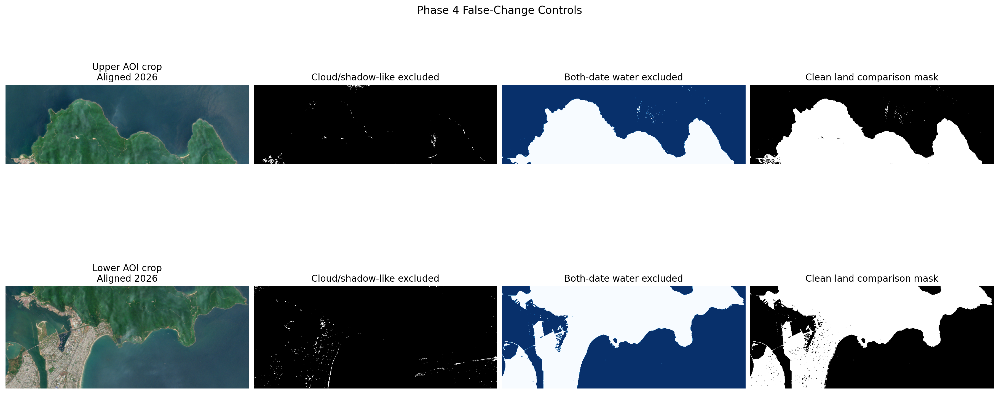

In [7]:
control_rows = []
fig, axes = plt.subplots(len(crops), 4, figsize=(18, 8), constrained_layout=True)

for row_idx, (crop_key, crop_label) in enumerate(crops.items()):
    a2024 = analysis_data[("2024", crop_key)]
    a2026 = analysis_data[("2026_aligned", crop_key)]
    scene_2026 = scene_data[("2026_aligned", crop_key)]

    valid = a2026["valid_mask"]
    cloud_shadow = (a2024["cloud"] | a2026["cloud"] | a2024["shadow"] | a2026["shadow"]) & valid
    both_water = (a2024["water"] & a2026["water"]) & valid
    clean_valid = change_maps[crop_key]["clean_valid"]
    strong_change = change_maps[crop_key]["strong_change"]

    control_rows.append({
        "crop": crop_key,
        "valid_pixels": int(np.count_nonzero(valid)),
        "cloud_shadow_excluded_pixels": int(np.count_nonzero(cloud_shadow)),
        "both_water_excluded_pixels": int(np.count_nonzero(both_water)),
        "clean_land_pixels": int(np.count_nonzero(clean_valid)),
        "strong_change_pixels": int(np.count_nonzero(strong_change)),
        "strong_change_percent_of_clean_land": float(np.count_nonzero(strong_change) / np.count_nonzero(clean_valid) * 100.0) if np.any(clean_valid) else 0.0,
    })

    axes[row_idx, 0].imshow(scene_2026["rgb"])
    axes[row_idx, 0].set_title(f"{crop_label}\nAligned 2026")
    axes[row_idx, 1].imshow(cloud_shadow, cmap="gray")
    axes[row_idx, 1].set_title("Cloud/shadow-like excluded")
    axes[row_idx, 2].imshow(both_water, cmap="Blues")
    axes[row_idx, 2].set_title("Both-date water excluded")
    axes[row_idx, 3].imshow(clean_valid, cmap="gray")
    axes[row_idx, 3].set_title("Clean land comparison mask")
    for col_idx in range(4):
        axes[row_idx, col_idx].axis("off")

fig.suptitle("Phase 4 False-Change Controls", fontsize=14)
save_figure(fig, "phase4_false_change_controls.png")
plt.show()

control_csv = output_dir / "phase4_false_change_controls.csv"
with control_csv.open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(control_rows[0].keys()))
    writer.writeheader()
    writer.writerows(control_rows)
print(f"Saved: {control_csv}")

print("\nFalse-change control summary")
for row in control_rows:
    print(
        f"- {row['crop']}: clean land={row['clean_land_pixels']} px, "
        f"strong change={row['strong_change_pixels']} px "
        f"({row['strong_change_percent_of_clean_land']:.2f}% of clean land), "
        f"cloud/shadow excluded={row['cloud_shadow_excluded_pixels']} px"
    )


## Phase 4 Notes
The detection target is built-up / urban-proxy land cover. Because only visible, Red, Green, Blue, and NIR bands are available, this is not a full urban classifier using SWIR/NDBI. The detector reuses the Phase 2 segmentation logic: water is suppressed with NDWI and dark-water rules, vegetation is suppressed with NDVI, and bright low-to-moderate saturation non-water/non-vegetation pixels are labeled as built-up/urban proxy.

Change tracking is treated as the satellite analogue of object tracking: each candidate changed region is represented as a fixed ROI in the 2024 coordinate frame, then the same ROI is inspected in the aligned 2026 frame. The notebook reports class percentages, NDVI delta, and a change interpretation for each tracked ROI.

Likely false-change sources are cloud/haze, shadows, water turbidity, sun-angle/radiometric differences, and small residual registration errors. Controls used here include same-month image dates, Phase 3 SIFT/RANSAC co-registration, exclusion of both-date water, exclusion of simple cloud/shadow-like pixels, connected-component filtering, and reporting candidate regions rather than treating every pixel difference as a real land-cover change.
